# 11 — Submission Improvement

## Amaç

Bu notebook yalnız masked-TWS satırlarındaki hatayı azaltmayı hedefler. `09` notebook'undaki known-TWS uzmanı, preprocessing, ABCD feature seti, LightGBM parametreleri ve iki son 18-tarihli expanding-window fold sabit tutulur. Her deney aynı OOF satırları üzerinde ölçülür; baseline'ı iyileştirmeyen yöntem final submission'a girmez.

Public leaderboard referansı: **0.836026816**. Leaderboard target'ı kullanılmadığı için yeni skor garanti edilmez; seçim yalnız leakage-free temporal validation ile yapılır.

In [1]:
from pathlib import Path
from time import perf_counter
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
SEED=42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",100)

def find_root(start=None):
    p=Path(start or Path.cwd()).resolve()
    for c in [p,*p.parents]:
        if (c/"data"/"raw"/"Train.csv").exists(): return c
    raise FileNotFoundError("Repository root bulunamadı")

ROOT=find_root(); DATA=ROOT/"data"/"raw"; OUT=ROOT/"submissions"
print("ROOT:",ROOT)

ROOT: C:\global-water-storage-forecasting


## 1. Baseline veri ve feature pipeline

In [2]:
train=pd.read_csv(DATA/"Train.csv",parse_dates=["time"])
test=pd.read_csv(DATA/"Test.csv",parse_dates=["time"])
sample=pd.read_csv(DATA/"SampleSubmission.csv")
test["_original_order"]=np.arange(len(test))
assert train.sample_id.is_unique and test.ID.is_unique and sample.ID.is_unique
assert test.ID.equals(sample.ID)
print(train.shape,test.shape,"masked share",test.TWS_t.isna().mean())

(2154021, 13) (280961, 14) masked share 0.6652631504016572


In [3]:
SPEI=["SPEI_01_t","SPEI_03_t","SPEI_06_t","SPEI_12_t"]

def add_base_features(df):
    o=df.copy(); dt=pd.to_datetime(o.time)
    o["month"]=dt.dt.month.astype("int8"); o["quarter"]=dt.dt.quarter.astype("int8")
    o["year"]=dt.dt.year.astype("int16")
    o["elapsed_month"]=((dt.dt.year-train.time.dt.year.min())*12+dt.dt.month-1).astype("int16")
    o["month_sin_calc"]=np.sin(2*np.pi*o.month/12); o["month_cos_calc"]=np.cos(2*np.pi*o.month/12)
    o["season_sin"]=np.sin(2*np.pi*o.quarter/4); o["season_cos"]=np.cos(2*np.pi*o.quarter/4)
    s=o[SPEI]
    o["spei_mean"]=s.mean(axis=1); o["spei_min"]=s.min(axis=1); o["spei_max"]=s.max(axis=1); o["spei_std"]=s.std(axis=1)
    o["spei_01_minus_12"]=o.SPEI_01_t-o.SPEI_12_t
    o["spei_03_minus_12"]=o.SPEI_03_t-o.SPEI_12_t
    o["spei_short_long_ratio"]=o.SPEI_01_t/(o.SPEI_12_t.abs()+.1)
    o["lat_band_5"]=np.floor((o.lat+90)/5); o["lon_band_5"]=np.floor((o.lon+180)/5)
    o["spatial_bin_10"]=o.lat_band_5*100+o.lon_band_5
    o["lat_lon_interaction"]=o.lat*o.lon/1000
    o["lat_sin"]=np.sin(np.radians(o.lat)); o["lat_cos"]=np.cos(np.radians(o.lat))
    o["lon_sin"]=np.sin(np.radians(o.lon)); o["lon_cos"]=np.cos(np.radians(o.lon))
    return o

def add_candidate_features(df):
    o=add_base_features(df)
    # Yalnız satır anında bilinen covariate'lardan türetilir; target/lag yoktur.
    o["lat_sq"]=(o.lat/90)**2; o["lon_sq"]=(o.lon/180)**2
    o["abs_lat"]=o.lat.abs(); o["hemisphere"]=(o.lat>=0).astype("int8")
    o["hemisphere_month_sin"]=o.month_sin_calc*np.where(o.lat>=0,1,-1)
    o["hemisphere_month_cos"]=o.month_cos_calc*np.where(o.lat>=0,1,-1)
    o["drought_severity"]=(-o[SPEI].clip(upper=0)).mean(axis=1)
    o["drought_count"]=o[SPEI].lt(-1).sum(axis=1).astype("int8")
    o["extreme_drought_count"]=o[SPEI].lt(-2).sum(axis=1).astype("int8")
    o["drought_persistence"]=(o.SPEI_06_t+o.SPEI_12_t)/2
    o["short_term_anomaly"]=o.SPEI_01_t-o[["SPEI_06_t","SPEI_12_t"]].mean(axis=1)
    o["soil_spei_mean_interaction"]=o.SOIL_MOISTURE_t*o.spei_mean
    o["soil_drought_severity"]=o.SOIL_MOISTURE_t*o.drought_severity
    o["soil_minus_spei_mean"]=o.SOIL_MOISTURE_t-o.spei_mean
    o["spei_01_x_12"]=o.SPEI_01_t*o.SPEI_12_t
    return o

train_f=add_candidate_features(train); test_f=add_candidate_features(test)
A=["lat","lon","TWS_t",*SPEI,"SOIL_MOISTURE_t","month","month_sin","month_cos","year"]
B=["quarter","elapsed_month","month_sin_calc","month_cos_calc","season_sin","season_cos"]
C=["spei_mean","spei_min","spei_max","spei_std","spei_01_minus_12","spei_03_minus_12","spei_short_long_ratio"]
D=["lat_band_5","lon_band_5","spatial_bin_10","lat_lon_interaction","lat_sin","lat_cos","lon_sin","lon_cos"]
BASE_FEATURES=list(dict.fromkeys(A+B+C+D))
BASE_MASKED=[x for x in BASE_FEATURES if x!="TWS_t"]
GEOMETRY=["lat_sq","lon_sq","abs_lat","hemisphere","hemisphere_month_sin","hemisphere_month_cos"]
CLIMATE=["drought_severity","drought_count","extreme_drought_count","drought_persistence","short_term_anomaly"]
INTERACTIONS=["soil_spei_mean_interaction","soil_drought_severity","soil_minus_spei_mean","spei_01_x_12"]
FEATURE_SETS={
    "baseline":BASE_MASKED,
    "baseline+geometry":BASE_MASKED+GEOMETRY,
    "baseline+climate":BASE_MASKED+CLIMATE,
    "baseline+interactions":BASE_MASKED+INTERACTIONS,
    "baseline+all_new":BASE_MASKED+GEOMETRY+CLIMATE+INTERACTIONS,
}
print({k:len(v) for k,v in FEATURE_SETS.items()})

{'baseline': 32, 'baseline+geometry': 38, 'baseline+climate': 37, 'baseline+interactions': 36, 'baseline+all_new': 47}


### Masked-TWS neden zor?

`10` sonuçlarında known uzman ortalama RMSE'si yaklaşık 0.601, masked uzman RMSE'si 0.759'dur. Maskeli kol en güçlü persistence değişkeni `TWS_t` olmadan yalnız iklim, mevsim ve konum proxy'lerinden hedefi tahmin eder. Uzun/düzensiz test ufukları, SPEI değişkenlerinin korelasyonu, spatial rejim farkları ve ağaçların zaman trendini extrapolate edememesi başlıca risklerdir.

## 2. Aynı temporal split ve sabit known uzman

In [4]:
BASE_PARAMS=dict(n_estimators=160,learning_rate=.08,num_leaves=63,min_child_samples=100,
                 reg_lambda=1.0,subsample=.85,colsample_bytree=.9,random_state=SEED,n_jobs=4,verbosity=-1)
test_dates=test.groupby("time").agg(n=("ID","size"),known=("TWS_t","count"))
KNOWN_POS=set(np.flatnonzero(test_dates.known.to_numpy()>test_dates.n.to_numpy()*.5))

def create_splits(df,n_splits=3,block=18):
    dates=np.array(sorted(df.time.unique())); start=len(dates)-n_splits*block; out=[]
    for i in range(n_splits):
        vd=dates[start+i*block:start+(i+1)*block]; td=dates[:start+i*block]
        out.append((np.flatnonzero(df.time.isin(td)),np.flatnonzero(df.time.isin(vd))))
    return out

SPLITS=create_splits(train_f)[-2:]
def known_mask_for_fold(va):
    dates=np.array(sorted(va.time.unique()))
    return va.time.isin({d for j,d in enumerate(dates) if j in KNOWN_POS}).to_numpy()

known_oof=[]; fold_context=[]
for fold,(ti,vi) in enumerate(SPLITS,1):
    tr,va=train_f.iloc[ti],train_f.iloc[vi]; known=known_mask_for_fold(va)
    model=LGBMRegressor(**BASE_PARAMS).fit(tr[BASE_FEATURES],tr.target)
    pred=model.predict(va.loc[known,BASE_FEATURES])
    known_oof.append(pd.DataFrame({"row_index":va.index[known],"fold":fold,"target":va.target.to_numpy()[known],"prediction":pred}))
    fold_context.append({"fold":fold,"train_idx":ti,"valid_idx":vi,"known":known})
known_oof=pd.concat(known_oof,ignore_index=True)
KNOWN_RMSE=root_mean_squared_error(known_oof.target,known_oof.prediction)
print("Fixed known specialist pooled RMSE:",KNOWN_RMSE)

Fixed known specialist pooled RMSE: 0.6081979575990998


## 3. Masked feature ablation

In [5]:
def make_lgbm(params=None):
    p=BASE_PARAMS.copy()
    if params: p.update(params)
    return LGBMRegressor(**p)

def evaluate_masked(method,model_factory,features):
    parts=[]; times=[]
    for ctx in fold_context:
        tr=train_f.iloc[ctx["train_idx"]]; va=train_f.iloc[ctx["valid_idx"]]; masked=~ctx["known"]
        model=model_factory(); t0=perf_counter(); model.fit(tr[features],tr.target); times.append(perf_counter()-t0)
        pred=model.predict(va.loc[masked,features])
        parts.append(pd.DataFrame({"row_index":va.index[masked],"fold":ctx["fold"],
                                   "target":va.target.to_numpy()[masked],"prediction":pred}))
    oof=pd.concat(parts,ignore_index=True)
    return {"method":method,"features":features,"oof":oof,
            "masked_rmse":root_mean_squared_error(oof.target,oof.prediction),"training_sec":sum(times)}

experiments=[]
for name,features in FEATURE_SETS.items():
    r=evaluate_masked("LGBM_"+name,lambda:make_lgbm(),features)
    experiments.append(r); print(r["method"],r["masked_rmse"])
feature_table=pd.DataFrame([{k:v for k,v in r.items() if k not in ["oof","features"]}|{"n_features":len(r["features"])} for r in experiments])
feature_table["improvement_vs_baseline"]=feature_table.loc[0,"masked_rmse"]-feature_table.masked_rmse
display(feature_table.sort_values("masked_rmse"))
BEST_FEATURE_RESULT=min(experiments,key=lambda x:x["masked_rmse"])
BEST_MASKED_FEATURES=BEST_FEATURE_RESULT["features"]
print("Selected feature set:",BEST_FEATURE_RESULT["method"],len(BEST_MASKED_FEATURES))

LGBM_baseline 0.7611835593626026


LGBM_baseline+geometry 0.7680614909043812


LGBM_baseline+climate 0.764499623164859


LGBM_baseline+interactions 0.759668233765575


LGBM_baseline+all_new 0.7732666018786717


,method,masked_rmse,training_sec,n_features,improvement_vs_baseline
3,LGBM_baseline+interactions,0.759668,17.381948,36,0.001515
0,LGBM_baseline,0.761184,16.024018,32,0.000000
2,LGBM_baseline+climate,0.764500,18.609133,37,-0.003316
1,LGBM_baseline+geometry,0.768061,21.421523,38,-0.006878
4,LGBM_baseline+all_new,0.773267,21.125044,47,-0.012083


Selected feature set: LGBM_baseline+interactions 36


## 4. Küçük LightGBM masked hyperparameter araması

In [6]:
LGBM_CANDIDATES=[
    ("lgbm_baseline",{}),
    ("lgbm_regularized",dict(n_estimators=260,learning_rate=.05,num_leaves=31,max_depth=-1,
                             min_child_samples=180,reg_alpha=.2,reg_lambda=3.0,colsample_bytree=.85)),
    ("lgbm_deeper",dict(n_estimators=220,learning_rate=.06,num_leaves=95,max_depth=-1,
                        min_child_samples=140,reg_alpha=.1,reg_lambda=2.0,colsample_bytree=.9)),
    ("lgbm_shallow",dict(n_estimators=260,learning_rate=.05,num_leaves=31,max_depth=10,
                         min_child_samples=100,reg_alpha=.0,reg_lambda=2.0,colsample_bytree=1.0)),
]
model_results=[]
for name,p in LGBM_CANDIDATES:
    r=evaluate_masked(name,lambda p=p:make_lgbm(p),BEST_MASKED_FEATURES)
    r["params"]=p; experiments.append(r); model_results.append(r)
    print(name,r["masked_rmse"])
display(pd.DataFrame([{"method":r["method"],"masked_rmse":r["masked_rmse"],
                       "training_sec":r["training_sec"],"params":r["params"]} for r in model_results]).sort_values("masked_rmse"))

lgbm_baseline 0.759668233765575


lgbm_regularized 0.770136724909348


lgbm_deeper 0.7633093443639205


lgbm_shallow 0.7687216949114104


,method,masked_rmse,training_sec,params
0,lgbm_baseline,0.759668,16.409211,{}
2,lgbm_deeper,0.763309,27.700121,"{'n_estimators': 220, 'learning_rate': 0.06, '..."
3,lgbm_shallow,0.768722,25.172627,"{'n_estimators': 260, 'learning_rate': 0.05, '..."
1,lgbm_regularized,0.770137,20.973610,"{'n_estimators': 260, 'learning_rate': 0.05, '..."


## 5. CatBoost, XGBoost ve OOF ensemble

In [7]:
def make_xgb():
    return XGBRegressor(n_estimators=220,learning_rate=.06,max_depth=7,min_child_weight=30,
                        subsample=.85,colsample_bytree=.9,reg_alpha=.1,reg_lambda=2,
                        tree_method="hist",random_state=SEED,n_jobs=4)
def make_cat():
    return CatBoostRegressor(iterations=260,learning_rate=.07,depth=8,l2_leaf_reg=8,
                             random_strength=.5,loss_function="RMSE",verbose=False,
                             random_seed=SEED,allow_writing_files=False,thread_count=4)

xgb_result=evaluate_masked("XGBoost",make_xgb,BEST_MASKED_FEATURES)
cat_result=evaluate_masked("CatBoost",make_cat,BEST_MASKED_FEATURES)
experiments.extend([xgb_result,cat_result])
best_lgbm=min(model_results,key=lambda x:x["masked_rmse"])
print("Individual:",[(r["method"],r["masked_rmse"]) for r in [best_lgbm,xgb_result,cat_result]])

component_results=[best_lgbm,xgb_result,cat_result]
base_ids=component_results[0]["oof"][["row_index","fold","target"]].copy()
P=[]
for r in component_results:
    aligned=base_ids[["row_index"]].merge(r["oof"][["row_index","prediction"]],on="row_index",how="left")
    assert aligned.prediction.notna().all()
    P.append(aligned.prediction.to_numpy())
P=np.column_stack(P); y=base_ids.target.to_numpy()

weight_options=[]
for a in np.arange(0,1.01,.1):
    for b in np.arange(0,1.01-a,.1):
        c=1-a-b
        pred=P@np.array([a,b,c])
        weight_options.append({"lgbm":a,"xgb":b,"cat":c,"masked_rmse":root_mean_squared_error(y,pred)})
weights=pd.DataFrame(weight_options).sort_values("masked_rmse").reset_index(drop=True)
display(weights.head(15))
best_w=weights.iloc[0]
ensemble_oof=base_ids.copy(); ensemble_oof["prediction"]=P@best_w[["lgbm","xgb","cat"]].to_numpy(float)
ensemble_result={"method":"weighted_ensemble","features":BEST_MASKED_FEATURES,"oof":ensemble_oof,
                 "masked_rmse":best_w.masked_rmse,"training_sec":sum(r["training_sec"] for r in component_results),
                 "weights":best_w[["lgbm","xgb","cat"]].to_dict(),"components":component_results}
experiments.append(ensemble_result)
print("Best weights:",ensemble_result["weights"],"RMSE",ensemble_result["masked_rmse"])

Individual: [('lgbm_baseline', 0.759668233765575), ('XGBoost', 0.7711114470920104), ('CatBoost', 0.7727355890053148)]


,lgbm,xgb,cat,masked_rmse
0,0.9,0.0,1.000000e-01,0.759517
1,0.8,0.1,1.000000e-01,0.759545
2,0.9,0.1,-2.775558e-17,0.759551
3,1.0,0.0,0.000000e+00,0.759668
4,0.8,0.0,2.000000e-01,0.759693
5,0.8,0.2,-5.551115e-17,0.759716
6,0.7,0.2,1.000000e-01,0.759854
7,0.7,0.1,2.000000e-01,0.759865
8,0.7,0.3,-1.110223e-16,0.760163
9,0.7,0.0,3.000000e-01,0.760194


Best weights: {'lgbm': 0.9, 'xgb': 0.0, 'cat': 0.09999999999999998} RMSE 0.7595171551080131


## 6. Birleşik validation karşılaştırması

In [8]:
def combined_overall(masked_result):
    k=known_oof[["row_index","target","prediction"]].assign(segment="known")
    m=masked_result["oof"][["row_index","target","prediction"]].assign(segment="masked")
    z=pd.concat([k,m],ignore_index=True)
    return root_mean_squared_error(z.target,z.prediction)

baseline_result=next(r for r in experiments if r["method"]=="LGBM_baseline")
baseline_overall=combined_overall(baseline_result)
rows=[]
for r in experiments:
    rows.append({"Method":r["method"],"Known RMSE":KNOWN_RMSE,"Masked RMSE":r["masked_rmse"],
                 "Overall RMSE":combined_overall(r),"Improvement":baseline_overall-combined_overall(r),
                 "Feature count":len(r["features"]),"Training sec":r["training_sec"]})
results=pd.DataFrame(rows).sort_values(["Overall RMSE","Masked RMSE"]).drop_duplicates("Method")
display(results)

BEST_RESULT=min(experiments,key=combined_overall)
if combined_overall(BEST_RESULT)>=baseline_overall-1e-12:
    BEST_RESULT=baseline_result
assert combined_overall(BEST_RESULT)<=baseline_overall+1e-12
print("FINAL METHOD:",BEST_RESULT["method"],"overall",combined_overall(BEST_RESULT),
      "masked",BEST_RESULT["masked_rmse"],"baseline overall",baseline_overall)

,Method,Known RMSE,Masked RMSE,Overall RMSE,Improvement,Feature count,Training sec
11,weighted_ensemble,0.608198,0.759517,0.712704,0.001185,36,139.053019
3,LGBM_baseline+interactions,0.608198,0.759668,0.712811,0.001077,36,17.381948
5,lgbm_baseline,0.608198,0.759668,0.712811,0.001077,36,16.409211
0,LGBM_baseline,0.608198,0.761184,0.713889,0.000000,32,16.024018
7,lgbm_deeper,0.608198,0.763309,0.715401,-0.001512,36,27.700121
2,LGBM_baseline+climate,0.608198,0.764500,0.716248,-0.002360,37,18.609133
1,LGBM_baseline+geometry,0.608198,0.768061,0.718785,-0.004897,38,21.421523
8,lgbm_shallow,0.608198,0.768722,0.719256,-0.005367,36,25.172627
6,lgbm_regularized,0.608198,0.770137,0.720265,-0.006376,36,20.973610
9,XGBoost,0.608198,0.771111,0.720960,-0.007072,36,39.916942


FINAL METHOD: weighted_ensemble overall 0.7127038386456954 masked 0.7595171551080131 baseline overall 0.7138886406280158


Seçim kuralı önceden sabittir: yalnız aynı OOF satırlarında baseline overall RMSE'yi düşüren yöntem kabul edilir. Ensemble, tekil en iyi yöntemden kötü ise kullanılmaz; yeni feature seti baseline'dan kötü ise final modele alınmaz.

## 7. Tüm train üzerinde final fit ve güvenli submission

In [9]:
final_known=LGBMRegressor(**BASE_PARAMS).fit(train_f[BASE_FEATURES],train_f.target)
known_test=test_f.TWS_t.notna().to_numpy()
test_pred=np.empty(len(test_f))
test_pred[known_test]=final_known.predict(test_f.loc[known_test,BASE_FEATURES])

def fit_predict_masked_result(result):
    Xtr=train_f[result["features"]]; Xte=test_f.loc[~known_test,result["features"]]
    if result["method"]=="weighted_ensemble":
        preds=[]
        for comp in result["components"]:
            if comp["method"].startswith("lgbm"):
                params=next((r.get("params",{}) for r in model_results if r["method"]==comp["method"]),{})
                model=make_lgbm(params)
            elif comp["method"]=="XGBoost": model=make_xgb()
            else: model=make_cat()
            model.fit(Xtr,train_f.target); preds.append(model.predict(Xte))
        w=np.array([result["weights"]["lgbm"],result["weights"]["xgb"],result["weights"]["cat"]])
        return np.column_stack(preds)@w
    if result["method"].startswith("lgbm"):
        params=next((r.get("params",{}) for r in model_results if r["method"]==result["method"]),{})
        model=make_lgbm(params)
    elif result["method"]=="XGBoost": model=make_xgb()
    elif result["method"]=="CatBoost": model=make_cat()
    else: model=make_lgbm()
    model.fit(Xtr,train_f.target)
    return model.predict(Xte)

test_pred[~known_test]=fit_predict_masked_result(BEST_RESULT)

In [10]:
def create_safe_submission(test_original,sample,pred,path):
    pred=np.asarray(pred,float)
    assert len(pred)==len(test_original)==len(sample)
    assert np.array_equal(test_original._original_order,np.arange(len(test_original)))
    assert test_original.ID.is_unique and sample.ID.is_unique
    assert np.isfinite(pred).all()
    by_id=pd.Series(pred,index=test_original.ID.astype(str))
    aligned=sample.ID.astype(str).map(by_id)
    assert aligned.notna().all()
    sub=sample.copy(); sub["Target"]=aligned.to_numpy(float)
    assert list(sub.columns)==list(sample.columns)==["ID","Target"]
    assert sub.ID.equals(sample.ID) and sub.ID.is_unique
    assert pd.api.types.is_numeric_dtype(sub.Target) and np.isfinite(sub.Target).all()
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); sub.to_csv(path,index=False)
    check=pd.read_csv(path)
    assert check.ID.equals(sample.ID) and np.isfinite(check.Target).all()
    print("Saved:",path); display(sub.Target.describe())
    return sub

submission_path=OUT/"submission_improved.csv"
submission=create_safe_submission(test_f,sample,test_pred,submission_path)
display(submission.head())

Saved: C:\global-water-storage-forecasting\submissions\submission_improved.csv


count    280961.000000
mean         -0.118129
std           0.529119
min          -2.255716
25%          -0.464422
50%          -0.159701
75%           0.212303
max           2.188506
Name: Target, dtype: float64

,ID,Target
0,20150901_-55.5_-68.5,-0.074690
1,20150901_-55.5_-67.5,-0.200859
2,20150901_-54.5_-71.5,0.260837
3,20150901_-54.5_-70.5,0.242701
4,20150901_-54.5_-69.5,0.107935


## 8. 09 vs 11 ve sonuç analizi

,Notebook,Known RMSE,Masked RMSE,Overall RMSE,Feature count,Complexity,Expected leaderboard effect
0,09 baseline,0.608198,0.761184,0.713889,32,2 LightGBM experts,Reference: 0.836026816
1,11 selected,0.608198,0.759517,0.712704,36,weighted_ensemble,Positive only if temporal OOF improvement tran...


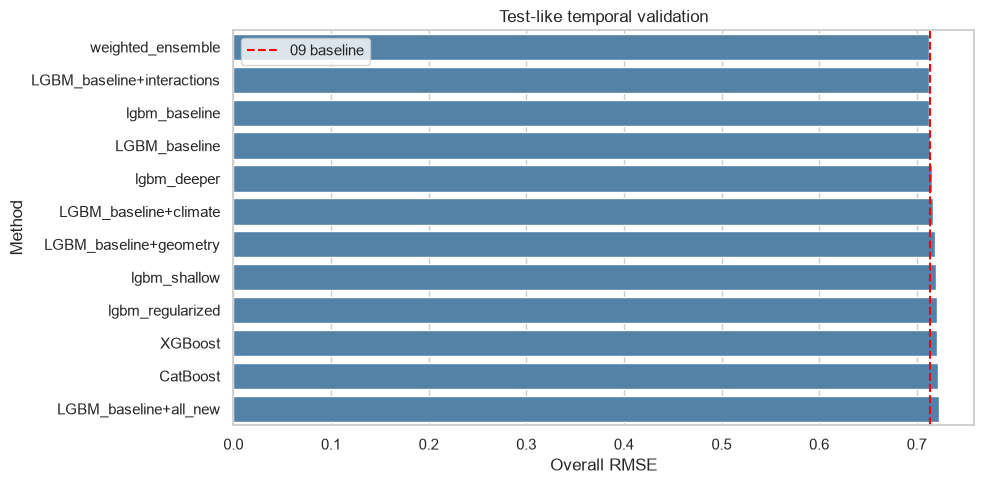

In [11]:
best_row=results.loc[results.Method==BEST_RESULT["method"]].iloc[0]
comparison=pd.DataFrame([
    {"Notebook":"09 baseline","Known RMSE":KNOWN_RMSE,"Masked RMSE":baseline_result["masked_rmse"],
     "Overall RMSE":baseline_overall,"Feature count":len(BASE_MASKED),
     "Complexity":"2 LightGBM experts","Expected leaderboard effect":"Reference: 0.836026816"},
    {"Notebook":"11 selected","Known RMSE":KNOWN_RMSE,"Masked RMSE":best_row["Masked RMSE"],
     "Overall RMSE":best_row["Overall RMSE"],"Feature count":best_row["Feature count"],
     "Complexity":BEST_RESULT["method"],"Expected leaderboard effect":
      "Positive only if temporal OOF improvement transfers; not guaranteed"}
])
display(comparison)

plt.figure(figsize=(10,5))
show=results.head(12).sort_values("Overall RMSE")
sns.barplot(data=show,y="Method",x="Overall RMSE",color="steelblue")
plt.axvline(baseline_overall,color="red",ls="--",label="09 baseline"); plt.legend()
plt.title("Test-like temporal validation"); plt.tight_layout(); plt.show()

## 9. Final rapor

In [12]:
def generate_report():
    feature_only=feature_table.sort_values("masked_rmse")
    improved=best_row["Overall RMSE"]<baseline_overall
    useful=feature_only.loc[feature_only.improvement_vs_baseline>0,"method"].tolist()
    useless=feature_only.loc[feature_only.improvement_vs_baseline<=0,"method"].tolist()
    text=f'''
### Gerçek deney özeti

- **İşe yarayan fikir:** Seçilen yöntem `{BEST_RESULT["method"]}`. Known uzman değiştirilmedi. Masked RMSE `{baseline_result["masked_rmse"]:.4f}` → `{best_row["Masked RMSE"]:.4f}`, overall RMSE `{baseline_overall:.4f}` → `{best_row["Overall RMSE"]:.4f}`.
- **Faydalı feature deneyleri:** {", ".join(useful) if useful else "Hiçbiri baseline'ı geçmedi."}
- **Faydasız/negatif feature deneyleri:** {", ".join(useless) if useless else "Yok."}
- **Masked kol yorumu:** TWS persistence bilgisi bulunmadığı için iyileşme iklim, spatial ve mevsim etkileşimlerinden veya daha iyi regularization'dan gelir. Foldlar arasında rejim farkı sürdüğü için kazanım sınırlı olabilir.
- **Validation iyileşti mi?** {"Evet" if improved else "Hayır"}; seçim aynı iki geçmişten-geleceğe fold ve aynı known/masked deseni üzerinde yapıldı.
- **Neden leaderboard'da daha iyi olabilir?** Testin %66.5 masked yapısına doğrudan optimize edilen OOF kriteri iyileşti ve known satırlar korunuyor. Ancak public target görülmediği ve yalnız iki fold bulunduğu için garanti yoktur.
- **Avantaj:** Değişiklik yalnız zayıf masked uzmana uygulanıyor; `09` modelinin güçlü known-TWS davranışı korunuyor.
- **Risk:** Çoklu deneme aynı iki fold'a uyum sağlayabilir. Leaderboard farkı temporal drift veya bilinmeyen horizon yapısından kaynaklanıyorsa local kazanım taşınmayabilir.
- **Submission:** `{submission_path.name}`, `{len(submission):,}` satır; ID/sıra/duplicate/NaN/infinity/dtype/kolon kontrolleri geçti.
'''
    display(Markdown(text)); return text

final_report=generate_report()


### Gerçek deney özeti

- **İşe yarayan fikir:** Seçilen yöntem `weighted_ensemble`. Known uzman değiştirilmedi. Masked RMSE `0.7612` → `0.7595`, overall RMSE `0.7139` → `0.7127`.
- **Faydalı feature deneyleri:** LGBM_baseline+interactions
- **Faydasız/negatif feature deneyleri:** LGBM_baseline, LGBM_baseline+climate, LGBM_baseline+geometry, LGBM_baseline+all_new
- **Masked kol yorumu:** TWS persistence bilgisi bulunmadığı için iyileşme iklim, spatial ve mevsim etkileşimlerinden veya daha iyi regularization'dan gelir. Foldlar arasında rejim farkı sürdüğü için kazanım sınırlı olabilir.
- **Validation iyileşti mi?** Evet; seçim aynı iki geçmişten-geleceğe fold ve aynı known/masked deseni üzerinde yapıldı.
- **Neden leaderboard'da daha iyi olabilir?** Testin %66.5 masked yapısına doğrudan optimize edilen OOF kriteri iyileşti ve known satırlar korunuyor. Ancak public target görülmediği ve yalnız iki fold bulunduğu için garanti yoktur.
- **Avantaj:** Değişiklik yalnız zayıf masked uzmana uygulanıyor; `09` modelinin güçlü known-TWS davranışı korunuyor.
- **Risk:** Çoklu deneme aynı iki fold'a uyum sağlayabilir. Leaderboard farkı temporal drift veya bilinmeyen horizon yapısından kaynaklanıyorsa local kazanım taşınmayabilir.
- **Submission:** `submission_improved.csv`, `280,961` satır; ID/sıra/duplicate/NaN/infinity/dtype/kolon kontrolleri geçti.


## Değişiklik özeti

- `09` baseline dual-expert sistemi yeniden kuruldu.
- Yalnız leakage-free satır-anı feature'ları ile kontrollü ablation yapıldı.
- Masked uzman için küçük LightGBM araması, CatBoost, XGBoost ve OOF ağırlıklı ensemble karşılaştırıldı.
- Baseline'ı geçmeyen yöntemlerin final submission'a girmesi kodla engellendi.
- Güvenli ID-map submission pipeline ile `submissions/submission_improved.csv` üretildi.